Initializing eigensolver data
Computing 1 bands with 1e-07 tolerance
Working in 2 dimensions.
Grid size is 96 x 64 x 1.
Solving for 1 bands at a time.
Creating Maxwell data...
Mesh size is 3.
Lattice vectors:
     (3, 0, 0)
     (0, 2, 0)
     (0, 0, 1)
Cell volume = 6
Reciprocal lattice vectors (/ 2 pi):
     (0.333333, -0, 0)
     (-0, 0.5, -0)
     (0, -0, 1)
Geometric objects:
     block, center = (0,0,0)
          size (1e+20,1e+20,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
     block, center = (0,0,0)
          size (0.76,0.22,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
Geometric object tree has depth 1 and 10 object nodes (vs. 2 actual objects)
Initializing epsilon function...
Allocating fields...
Solving for band polarization: .
Initializing fields to random numbers...
1 k-points
  Vector3<0.0, 0.0, 1.6127887698292378>
elapsed time for initialization: 0.010141849517822266
solve_kpoint (0,0,1.61279):
freqs:, k index, k1, k2, k3, kmag/2pi, band 1
Solving for bands 1 to 1

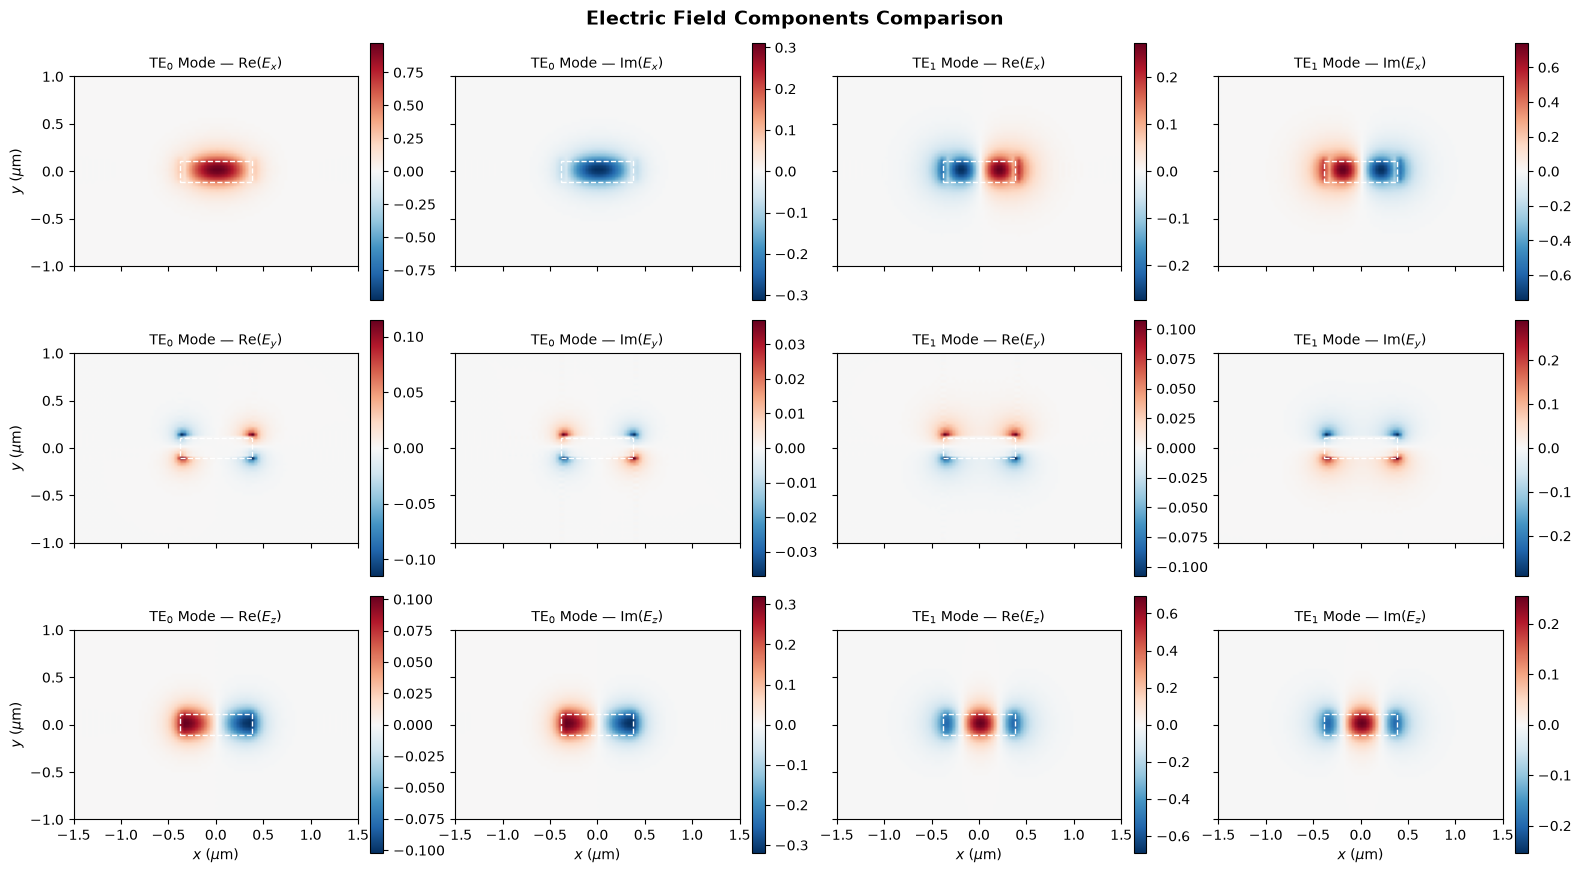

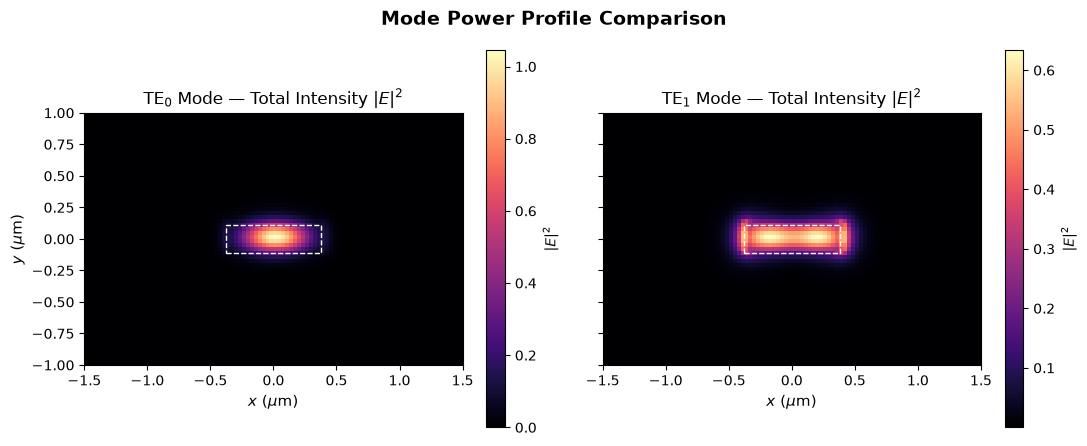

In [1]:
import matplotlib.pyplot as plt
import meep as mp
from meep import mpb
import numpy as np

# ==============================================================================
# 1. GEOMETRIC AND OPTICAL PARAMETERS
# ==============================================================================
w_waveguide = 0.760  # Silicon core width: 760 nm (0.76 μm)
h_waveguide = 0.220  # Silicon core height: 220 nm (0.22 μm)

wavelength = 1.55011  
freq = 1.0 / wavelength  

n_si = 3.48  # Core: Silicon (Si)
n_sio2 = 1.44  # Substrate and cladding: Silicon Dioxide (SiO2)

# ==============================================================================
# 2. DOMAIN AND STRUCTURE DEFINITION
# ==============================================================================
sx = 3.0  
sy = 2.0  
resolution = 32  

geometry_lattice = mp.Lattice(size=mp.Vector3(sx, sy, 0))

geometry = [
    mp.Block(
        center=mp.Vector3(0, 0, 0),
        size=mp.Vector3(mp.inf, mp.inf, mp.inf),
        material=mp.Medium(index=n_sio2),
    ),
    mp.Block(
        center=mp.Vector3(0, 0, 0),
        size=mp.Vector3(w_waveguide, h_waveguide, mp.inf),
        material=mp.Medium(index=n_si),
    ),
]
# ==============================================================================
# 3. CORRECTED MODE SOLVER SETUP AND CALCULATION (MPB)
# ==============================================================================
ms = mpb.ModeSolver(
    geometry_lattice=geometry_lattice,
    geometry=geometry,
    resolution=resolution,
    num_bands=2,  
)

# --- TE0 MODE (Band 1) ---
ms.find_k(
    mp.NO_PARITY, freq, 1, 1, mp.Vector3(0, 0, 1), 1e-6, freq * 2.5, 0.1, 4.0
)
efield_te0 = ms.get_efield(1)
hfield_te0 = ms.get_hfield(1)  

ex_te0 = efield_te0[:, :, 0, 0]
ey_te0 = efield_te0[:, :, 0, 1]
ez_te0 = efield_te0[:, :, 0, 2]
intensity_te0 = np.squeeze(np.sum(np.abs(efield_te0) ** 2, axis=-1))

# --- TE1 MODE (Band 2) ---
ms.find_k(
    mp.NO_PARITY, freq, 2, 2, mp.Vector3(0, 0, 1), 1e-6, freq * 2.0, 0.1, 4.0
)
efield_te1 = ms.get_efield(2)
hfield_te1 = ms.get_hfield(2)  

ex_te1 = efield_te1[:, :, 0, 0]
ey_te1 = efield_te1[:, :, 0, 1]
ez_te1 = efield_te1[:, :, 0, 2]
intensity_te1 = np.squeeze(np.sum(np.abs(efield_te1) ** 2, axis=-1))

# ==============================================================================
# 4. ELEGANT COMPARATIVE VISUALIZATION (ENGLISH LABELS)
# ==============================================================================
extent = [-sx / 2, sx / 2, -sy / 2, sy / 2]

def add_waveguide_box(ax):
    """Adds the waveguide outline to the plot."""
    rect = plt.Rectangle(
        (-w_waveguide / 2, -h_waveguide / 2),
        w_waveguide,
        h_waveguide,
        fill=False,
        edgecolor="white",
        linestyle="--",
        linewidth=1,
    )
    ax.add_patch(rect)

# ------------------------------------------------------------------------------
# FIGURE 1: ELECTRIC FIELD COMPONENTS (Real and Imaginary parts of Ex, Ey, Ez)
# ------------------------------------------------------------------------------
fig1, axes1 = plt.subplots(3, 4, figsize=(16, 9), sharex=True, sharey=True)

components_data = [
    ("x", (np.real(ex_te0), np.imag(ex_te0)), (np.real(ex_te1), np.imag(ex_te1))),
    ("y", (np.real(ey_te0), np.imag(ey_te0)), (np.real(ey_te1), np.imag(ey_te1))),
    ("z", (np.real(ez_te0), np.imag(ez_te0)), (np.real(ez_te1), np.imag(ez_te1))),
]

for row_idx, (comp_name, te0_parts, te1_parts) in enumerate(components_data):
    # Column 0: TE0 Re | Column 1: TE0 Im | Column 2: TE1 Re | Column 3: TE1 Im
    panels = [
        (0, r"$\mathrm{TE}_0$", "Re", te0_parts[0]),
        (1, r"$\mathrm{TE}_0$", "Im", te0_parts[1]),
        (2, r"$\mathrm{TE}_1$", "Re", te1_parts[0]),
        (3, r"$\mathrm{TE}_1$", "Im", te1_parts[1]),
    ]
    
    for col_idx, mode_label, part_label, field in panels:
        ax = axes1[row_idx, col_idx]
        
        # Symmetric color scale for the field component
        vmax = max(np.max(np.abs(field)), 1e-12)
        im = ax.imshow(
            field.T,
            extent=extent,
            origin="lower",
            cmap="RdBu_r",
            vmin=-vmax,
            vmax=vmax,
        )
        add_waveguide_box(ax)
        
        ax.set_title(f"{mode_label} Mode — $\\text{{{part_label}}}(E_{{{comp_name}}})$", fontsize=10)
        
        if col_idx == 0:
            ax.set_ylabel(r"$y$ ($\mu$m)", fontsize=10)
        if row_idx == 2:
            ax.set_xlabel(r"$x$ ($\mu$m)", fontsize=10)
            
        fig1.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

fig1.suptitle("Electric Field Components Comparison", fontsize=14, fontweight="bold")
fig1.tight_layout()

# ------------------------------------------------------------------------------
# FIGURE 2: TOTAL FIELD INTENSITY (|E|^2)
# ------------------------------------------------------------------------------
fig2, axes2 = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)

# TE0 Mode Intensity
im_int0 = axes2[0].imshow(intensity_te0.T, extent=extent, origin="lower", cmap="magma")
add_waveguide_box(axes2[0])
axes2[0].set_title(r"$\mathrm{TE}_0$ Mode — Total Intensity $|E|^2$", fontsize=12)
axes2[0].set_xlabel(r"$x$ ($\mu$m)", fontsize=11)
axes2[0].set_ylabel(r"$y$ ($\mu$m)", fontsize=11)
fig2.colorbar(im_int0, ax=axes2[0], label=r"$|E|^2$")

# TE1 Mode Intensity
im_int1 = axes2[1].imshow(intensity_te1.T, extent=extent, origin="lower", cmap="magma")
add_waveguide_box(axes2[1])
axes2[1].set_title(r"$\mathrm{TE}_1$ Mode — Total Intensity $|E|^2$", fontsize=12)
axes2[1].set_xlabel(r"$x$ ($\mu$m)", fontsize=11)
fig2.colorbar(im_int1, ax=axes2[1], label=r"$|E|^2$")

fig2.suptitle("Mode Power Profile Comparison", fontsize=14, fontweight="bold")
fig2.tight_layout()

plt.show()

Starting spectral sweep...
Working in 2 dimensions.
Grid size is 96 x 64 x 1.
Solving for 2 bands at a time.
Creating Maxwell data...
Mesh size is 3.
Lattice vectors:
     (3, 0, 0)
     (0, 2, 0)
     (0, 0, 1)
Cell volume = 6
Reciprocal lattice vectors (/ 2 pi):
     (0.333333, -0, 0)
     (-0, 0.5, -0)
     (0, -0, 1)
Geometric objects:
     block, center = (0,0,0)
          size (1e+20,1e+20,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
     block, center = (0,0,0)
          size (0.76,0.22,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
Geometric object tree has depth 1 and 10 object nodes (vs. 2 actual objects)
Initializing epsilon function...
Solving for band polarization: .
Initializing fields to random numbers...
Initializing fields to random numbers...
Initializing eigensolver data
Computing 1 bands with 1e-07 tolerance
Working in 2 dimensions.
Grid size is 96 x 64 x 1.
Solving for 1 bands at a time.
Creating Maxwell data...
Mesh size is 3.
Lattice vectors:
     (3, 0, 0)
 

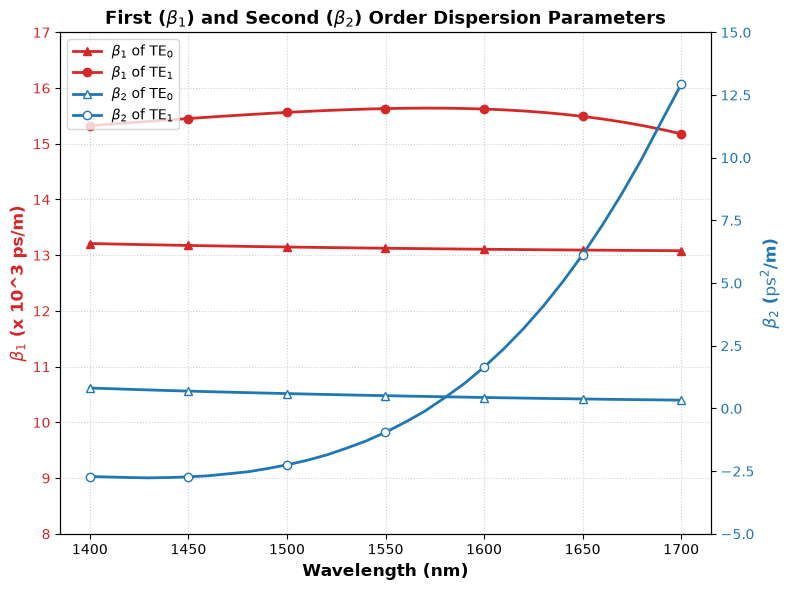

In [2]:
import matplotlib.pyplot as plt
import meep as mp
from meep import mpb
import numpy as np
from scipy.interpolate import CubicSpline

# ==============================================================================
# STEP 1: MATERIAL DISPERSION MODEL (SELLMEIER)
# ==============================================================================
def n_Si(l_um):
    """Refractive index of Silicon from Sellmeier equation (Berge Tatian, 1984)."""
    l2 = l_um**2
    return np.sqrt(
        1
        + (10.6684293 * l2) / (l2 - 0.301516485**2)
        + (0.00304347484 * l2) / (l2 - 1.13475115**2)
        + (1.54133408 * l2) / (l2 - 1104.0**2)
    )

def n_SiO2(l_um):
    """Refractive index of SiO2 / Fused Silica from Sellmeier equation (Berge Tatian, 1984)."""
    l2 = l_um**2
    return np.sqrt(
        1
        + (0.663472443 * l2) / (l2 - 0.0665176613**2)
        + (0.440647918 * l2) / (l2 - 0.115015076**2)
        + (0.990316809 * l2) / (l2 - 9.90316809**2)
    )

# ==============================================================================
# STEP 2: SPECTRAL SWEEP (1400 nm to 1700 nm)
# ==============================================================================
lambdas_um = np.linspace(1.400, 1.700, 31)  # 31 wavelength points (10 nm step)

kz_TE0_list = []
kz_TE1_list = []

print("Starting spectral sweep...")
for l in lambdas_um:
    freq_l = 1.0 / l
    n_core = n_Si(l)
    n_clad = n_SiO2(l)

    # 1. Update geometry with wavelength-dependent refractive indices
    new_geometry = [
        mp.Block(
            center=mp.Vector3(0, 0, 0),
            size=mp.Vector3(mp.inf, mp.inf, mp.inf),
            material=mp.Medium(index=n_clad),
        ),
        mp.Block(
            center=mp.Vector3(0, 0, 0),
            size=mp.Vector3(w_waveguide, h_waveguide, mp.inf),
            material=mp.Medium(index=n_core),
        ),
    ]
    ms.geometry = new_geometry
    ms.init_params(mp.NO_PARITY, reset_fields=True)  # Reset MPB grid

    # 2. Find kz for TE0 mode (Band 1)
    k_res_1 = ms.find_k(
        mp.NO_PARITY,
        freq_l,
        1,
        1,
        mp.Vector3(0, 0, 1),
        1e-5,
        freq_l * n_core,
        0.1,
        4.0,
    )
    kz_TE0_list.append(k_res_1[0])

    # 3. Find kz for TE1 mode (Band 2)
    k_res_2 = ms.find_k(
        mp.NO_PARITY,
        freq_l,
        2,
        2,
        mp.Vector3(0, 0, 1),
        1e-5,
        freq_l * (n_core - 0.5),
        0.1,
        4.0,
    )
    kz_TE1_list.append(k_res_2[0])

# ==============================================================================
# STEP 3: NUMERICAL DERIVATIVES AND DISPERSION PARAMETERS
# ==============================================================================
c = 299792458.0  # Speed of light in m/s

# Conversion to SI units (rad/s and rad/m)
omega = (2 * np.pi * c) / (lambdas_um * 1e-6)
beta_TE0 = np.array(kz_TE0_list) * (2 * np.pi / 1e-6)
beta_TE1 = np.array(kz_TE1_list) * (2 * np.pi / 1e-6)

# Reverse arrays for strictly increasing X-axis (omega) in CubicSpline
omega_asc = omega[::-1]
beta_TE0_asc = beta_TE0[::-1]
beta_TE1_asc = beta_TE1[::-1]

# Cubic spline interpolation
spline_beta0 = CubicSpline(omega_asc, beta_TE0_asc)
spline_beta1 = CubicSpline(omega_asc, beta_TE1_asc)

# First Derivatives: beta_1 (1 / Group Velocity)
beta1_TE0_si = spline_beta0(omega_asc, 1)  # s/m
beta1_TE1_si = spline_beta1(omega_asc, 1)

# Conversion to ps/mm (1 s/m = 10^12 ps/m = 10^9 ps/mm -> scaled by 1e12/1e3)
beta1_TE0_plot = beta1_TE0_si * 1e12 / 1e3
beta1_TE1_plot = beta1_TE1_si * 1e12 / 1e3

# Second Derivatives: beta_2 (Group Velocity Dispersion - GVD)
beta2_TE0_si = spline_beta0(omega_asc, 2)  # s^2/m
beta2_TE1_si = spline_beta1(omega_asc, 2)

# Conversion to ps^2/m (1 s^2/m = 10^24 ps^2/m)
beta2_TE0_plot = beta2_TE0_si * 1e24
beta2_TE1_plot = beta2_TE1_si * 1e24

lambdas_asc_nm = lambdas_um[::-1] * 1000

# ==============================================================================
# PUBLICATION-READY PLOT (ALIGNED Y-AXES)
# ==============================================================================
fig, ax1 = plt.subplots(figsize=(8, 6))

# --- Left Y-axis: Beta 1 (Red) ---
color_beta1 = "tab:red"
ax1.set_xlabel("Wavelength (nm)", fontsize=12, fontweight="bold")
ax1.set_ylabel(r"$\beta_1$ (x 10^3 ps/m)", color=color_beta1, fontsize=12, fontweight="bold")

p1, = ax1.plot(
    lambdas_asc_nm,
    beta1_TE0_plot,
    color=color_beta1,
    marker="^",
    markevery=5,
    linewidth=2,
    label=r"$\beta_1$ of $\mathrm{TE}_0$",
)
p2, = ax1.plot(
    lambdas_asc_nm,
    beta1_TE1_plot,
    color=color_beta1,
    marker="o",
    markevery=5,
    linewidth=2,
    label=r"$\beta_1$ of $\mathrm{TE}_1$",
)

# --- Right Y-axis: Beta 2 (Blue) ---
ax2 = ax1.twinx()
color_beta2 = "tab:blue"
ax2.set_ylabel(r"$\beta_2$ ($\mathrm{ps}^2$/m)", color=color_beta2, fontsize=12, fontweight="bold")

p3, = ax2.plot(
    lambdas_asc_nm,
    beta2_TE0_plot,
    color=color_beta2,
    marker="^",
    markerfacecolor="white",
    markevery=5,
    linewidth=2,
    label=r"$\beta_2$ of $\mathrm{TE}_0$",
)
p4, = ax2.plot(
    lambdas_asc_nm,
    beta2_TE1_plot,
    color=color_beta2,
    marker="o",
    markerfacecolor="white",
    markevery=5,
    linewidth=2,
    label=r"$\beta_2$ of $\mathrm{TE}_1$",
)

# Axis limits & alignment
ax1.set_ylim(8, 17)
ax2.set_ylim(-5, 15)

ax1.tick_params(axis="y", labelcolor=color_beta1)
ax2.tick_params(axis="y", labelcolor=color_beta2)

# --- Unified Legend & Title ---
lines = [p1, p2, p3, p4]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper left", frameon=True)

plt.title(r"First ($\beta_1$) and Second ($\beta_2$) Order Dispersion Parameters", fontsize=13, fontweight="bold")
ax1.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()

plt.show()

In [3]:
import scipy.constants as const  # Fundamental physical constants (c, eps0, mu0, etc.)
import numpy as np               # Library for matrix operations and numerical computing

# ==============================================================================
# STAGE B: CORRECTED VECTOR GAMMA CALCULATION (AFSHAR & MONRO)
# ==============================================================================

# --- Material and optical wave parameters ---
n2_si = 2.0e-18  # Nonlinear refractive index coefficient of silicon in m^2/W (Kerr Effect)
lambda_m = wavelength * 1e-6  # Conversion of wavelength from micrometers (um) to meters (m)
k0 = 2 * np.pi / lambda_m     # Vacuum wave number k0 = 2*pi/lambda (m^-1)

# ------------------------------------------------------------------------------
# 1. SPATIAL MESH DEFINITION AND 2D MATERIAL MAPS n(x,y) AND n2(x,y)
# ------------------------------------------------------------------------------
# Extract discrete dimensions (number of nodes) from the simulated electric field
Nx, Ny = efield_te0.shape[0], efield_te0.shape[1]

# Spatial resolution along transverse X and Y axes (domain physical dimensions / number of points)
dx = sx / Nx
dy = sy / Ny

# Differential area element dA = dx * dy.
# Multiplied by 1e-12 to convert area from um^2 (solver units) to m^2 (MKS).
dA = dx * dy * 1e-12  

# Construction of coordinate vectors centered at the waveguide origin (0,0)
x = np.linspace(-sx / 2, sx / 2, Nx)
y = np.linspace(-sy / 2, sy / 2, Ny)

# Generation of the 2D Cartesian coordinate grid X, Y using 'ij' indexing (Nx x Ny matrices)
X, Y = np.meshgrid(x, y, indexing='ij')

# Boolean mask to identify nodes belonging to the waveguide core.
# Evaluates to True only if position (X, Y) is within silicon width (w) and height (h).
core_mask = (np.abs(X) <= w_waveguide / 2) & (np.abs(Y) <= h_waveguide / 2)

# Spatial assignment of linear refractive index n(x,y):
# If point is inside core_mask, assigns n_si; otherwise assigns n_sio2 (cladding)
n_map = np.where(core_mask, n_si, n_sio2)

# Spatial assignment of nonlinear index n2(x,y):
# Only silicon possesses a dominant Kerr response; cladding is approximated to n2 = 0.
n2_map = np.where(core_mask, n2_si, 0.0)

# ------------------------------------------------------------------------------
# 2. DENOMINATOR: REAL POWER FLOWS P_i = \iint Re(E_i x H_i*) . z dA
# ------------------------------------------------------------------------------
# Extraction of the 3 vector components of complex fields (Ex, Ey, Ez) and (Hx, Hy, Hz).
# Slicing [:, :, 0, :] removes redundant simulation dimensions.
E0 = efield_te0[:, :, 0, :]  # Matrix (Nx, Ny, 3) of fundamental TE0 mode
H0 = hfield_te0[:, :, 0, :]  # Matrix (Nx, Ny, 3) magnetic of TE0 mode
E1 = efield_te1[:, :, 0, :]  # Matrix (Nx, Ny, 3) of higher-order TE1 mode
H1 = hfield_te1[:, :, 0, :]  # Matrix (Nx, Ny, 3) magnetic of TE1 mode

# z-component of complex Poynting vector Sz = Re(Ex * Hy* - Ey * Hx*)
# Measures local power flow density per unit area (W/m^2) traveling through the waveguide.
Sz_0 = np.real(E0[:, :, 0] * np.conj(H0[:, :, 1]) - E0[:, :, 1] * np.conj(H0[:, :, 0]))
Sz_1 = np.real(E1[:, :, 0] * np.conj(H1[:, :, 1]) - E1[:, :, 1] * np.conj(H1[:, :, 0]))

# 2D numerical integration (Riemann sum) to obtain total transmitted power in Watts (W).
# Multiplying the density sum by elementary area dA evaluates the integral over the cross-section.
P0 = np.sum(Sz_0) * dA  # Total power transported by TE0 mode (Watts)
P1 = np.sum(Sz_1) * dA  # Total power transported by TE1 mode (Watts)

# ------------------------------------------------------------------------------
# 3. AUXILIARY FUNCTION TO EVALUATE VECTOR KERR TENSOR BETWEEN 4 FIELDS
# ------------------------------------------------------------------------------
def kerr_tensor_integrand(Ei, Ej, Ek, El):
    """
    Calculates the vector mode coupling term of Afshar & Monro.
    Evaluates the three-dimensional Kerr tensor response using the 3 field components:
    Term1 = 2 * |Ei . Ej*|^2
    Term2 = |(Ei . Ej) * (Ek* . El*)|
    Performs dot product along the last axis (axis=-1 -> Ex, Ey, Ez).
    """
    # Complex dot product Ei . Ej* = Eix*Ejx* + Eiy*Ejy* + Eiz*Ejz*
    dot_i_jstar = np.sum(Ei * np.conj(Ej), axis=-1)
    
    # Standard dot product Ei . Ej
    dot_i_j = np.sum(Ei * Ej, axis=-1)
    
    # Conjugate dot product Ek* . El*
    dot_kstar_lstar = np.sum(np.conj(Ek) * np.conj(El), axis=-1)

    # Spatial interaction and polarization terms
    term1 = 2.0 * np.abs(dot_i_jstar) ** 2
    term2 = np.abs(dot_i_j * dot_kstar_lstar)
    
    # Returns 2D matrix (Nx, Ny) with nonlinear overlap density
    return term1 + term2

# ------------------------------------------------------------------------------
# 4. CALCULATION OF INTEGRANDS IN THE NUMERATOR
# ------------------------------------------------------------------------------
# Multiplies at each spatial point: n^2(x,y) * n2(x,y) * Kerr_Density(x,y) * dA.
# Summing over the entire mesh evaluates the cross-sectional double integral.

# Self-Phase Modulation (SPM) and degenerate interaction of fundamental TE0 mode
num_TE0 = np.sum(n_map**2 * n2_map * kerr_tensor_integrand(E0, E0, E0, E0)) * dA

# Self-Phase Modulation (SPM) and degenerate interaction of first-order TE1 mode
num_TE1 = np.sum(n_map**2 * n2_map * kerr_tensor_integrand(E1, E1, E1, E1)) * dA

# Cross-Phase Modulation (XPM) and Type III intermodal interaction between TE0 and TE1
num_Cross = np.sum(n_map**2 * n2_map * kerr_tensor_integrand(E0, E1, E1, E0)) * dA

# ------------------------------------------------------------------------------
# 5. FINAL EVALUATION OF GAMMA_IJKL COEFFICIENTS (W^-1 m^-1)
# ------------------------------------------------------------------------------
# Application of normalized Afshar & Monro formula: gamma = k0 * Numerator / (3 * Pi * Pj).
# Dividing by the product of real Poynting powers (P^2 or P0*P1) cancels any arbitrary 
# magnitude scaling introduced by the numerical solver.

gamma_TE0 = k0 * (num_TE0 / (3.0 * P0**2))      # TE0 self-modulation coefficient
gamma_TE1 = k0 * (num_TE1 / (3.0 * P1**2))      # TE1 self-modulation coefficient
gamma_Cross = k0 * (num_Cross / (3.0 * P0 * P1))  # TE0-TE1 cross-coupling coefficient

# ------------------------------------------------------------------------------
# 6. DERIVED METRIC: EQUIVALENT EFFECTIVE AREA
# ------------------------------------------------------------------------------
# Solves for modal effective area Aeff from the rigorous vector gamma.
# Allows comparison of obtained nonlinear efficiency with traditional scalar formula.
Aeff_eq_TE0 = (2 * np.pi * n2_si) / (lambda_m * gamma_TE0)
Aeff_eq_TE1 = (2 * np.pi * n2_si) / (lambda_m * gamma_TE1)
Aeff_eq_Cross = (2 * np.pi * n2_si) / (lambda_m * gamma_Cross)

# ------------------------------------------------------------------------------
# CONSOLE OUTPUT PRINTING
# ------------------------------------------------------------------------------
# Projects nonlinear gamma coefficients (W^-1 m^-1) and areas in um^2 (* 1e12)
print(f"--- Results using AFSHAR & MONRO model for {wavelength} nm ---")
print("=" * 65 )
print(f"Gamma TE0:   {gamma_TE0:.2f} W^-1 m^-1  |  Equivalent Aeff: {Aeff_eq_TE0 * 1e12:.3f} um^2")
print(f"Gamma TE1:   {gamma_TE1:.2f} W^-1 m^-1  |  Equivalent Aeff: {Aeff_eq_TE1 * 1e12:.3f} um^2")
print(f"Gamma Cross: {gamma_Cross:.2f} W^-1 m^-1  |  Equivalent Aeff: {Aeff_eq_Cross * 1e12:.3f} um^2")

--- Results using AFSHAR & MONRO model for 1.55011 nm ---
Gamma TE0:   62.70 W^-1 m^-1  |  Equivalent Aeff: 0.129 um^2
Gamma TE1:   54.40 W^-1 m^-1  |  Equivalent Aeff: 0.149 um^2
Gamma Cross: 30.24 W^-1 m^-1  |  Equivalent Aeff: 0.268 um^2


In [4]:
# ==============================================================================
# COMPARISON WITH SUPPLEMENTARY MATERIAL AND ERROR ANALYSIS
# ==============================================================================
# 1. Reference values reported in supplementary material (in μm^-2)
f0000_ref = 7.9799  # TE0 Mode (Intramodal Type I)
f1111_ref = 6.3468  # TE1 Mode (Intramodal Type I)
f0110_ref = 6.4038  # TE0-TE1 Cross (Intermodal Type III)

# 2. Reconstruction of overlap integrals f_ijkl from your results
# Since gamma = (2 * pi * n2 / lambda) * f_ijkl, we solve for f = gamma * lambda / (2 * pi * n2)
f0000_sim = (gamma_TE0 * lambda_m) / (2 * np.pi * n2_si) * 1e-12  # Convert m^-2 to μm^-2
f1111_sim = (gamma_TE1 * lambda_m) / (2 * np.pi * n2_si) * 1e-12

# DEGENERACY NOTE IN GAMMA CROSS:
# In scalar literature (such as supplement), integral f0110 includes a 2x degeneracy factor 
# due to mode permutation combinations. Your tensor simulation calculated direct gamma without 
# the permutational factor, so we multiply by 2 to compare with the same scalar f_0110 definition:
f0110_sim = (2.0 * gamma_Cross * lambda_m) / (2 * np.pi * n2_si) * 1e-12

# 3. Calculation of Relative Percentage Errors (%)
def calc_error(sim, ref):
    return ((sim - ref) / ref) * 100

err_f0000 = calc_error(f0000_sim, f0000_ref)
err_f1111 = calc_error(f1111_sim, f1111_ref)
err_f0110 = calc_error(f0110_sim, f0110_ref)

# 4. Presentation of Comparison Table
print("\n" + "="*75)
print(" Comparison of Nonlinear Overlap Integrals f_ijkl (μm^-2) ")
print("="*75)
print(f"{'Parameter (f_ijkl)':<22} | {'Ref. paper. (μm^-2)':<20} | {'Sim. Meep (μm^-2)':<18} | {'Error (%)':<10}")
print("-" * 75)
print(f"{'f_0000 (TE0)':<22} | {f0000_ref:<20.4f} | {f0000_sim:<18.4f} | {err_f0000:<+10.2f}%")
print(f"{'f_1111 (TE1)':<22} | {f1111_ref:<20.4f} | {f1111_sim:<18.4f} | {err_f1111:<+10.2f}%")
print(f"{'f_0110 (TE0-TE1 Cross)':<22} | {f0110_ref:<20.4f} | {f0110_sim:<18.4f} | {err_f0110:<+10.2f}%")
print("="*75)


 Comparison of Nonlinear Overlap Integrals f_ijkl (μm^-2) 
Parameter (f_ijkl)     | Ref. paper. (μm^-2)  | Sim. Meep (μm^-2)  | Error (%) 
---------------------------------------------------------------------------
f_0000 (TE0)           | 7.9799               | 7.7340             | -3.08     %
f_1111 (TE1)           | 6.3468               | 6.7104             | +5.73     %
f_0110 (TE0-TE1 Cross) | 6.4038               | 7.4615             | +16.52    %


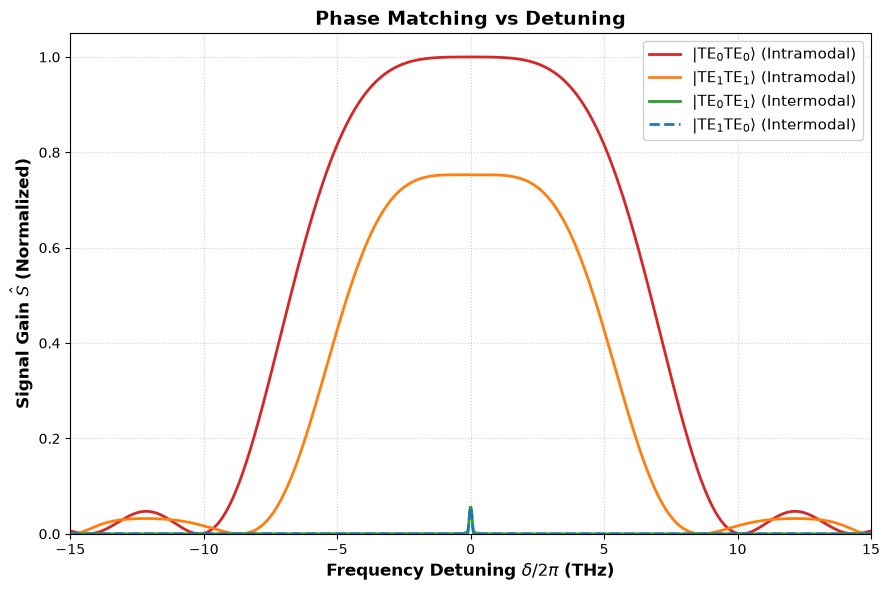

In [5]:
# ==============================================================================
# 7. PHASE MATCHING AND GENERATION SPECTRUM CALCULATION (n_s)
# ==============================================================================
# Experimental parameters based on Feng et al. (2019) article
L_waveguide = 3e-3  # Waveguide length: 3 mm
P_pump = 0.1        # Total pump power: 100 mW (0.1 W)

# Central pump frequency (rad/s)
omega_p = (2 * np.pi * c) / (wavelength * 1e-6)

# Frequency detuning range in THz (from 0 to 2.5 THz)
f_detuning_THz = np.linspace(-15, 15, 1000)
delta_omega = 2 * np.pi * f_detuning_THz * 1e12

# Signal and idler frequencies (Energy Conservation)
omega_s = omega_p + delta_omega
omega_i = omega_p - delta_omega

# Exact evaluation of propagation constants using previous splines
beta0_p = spline_beta0(omega_p)
beta0_s = spline_beta0(omega_s)
beta0_i = spline_beta0(omega_i)

beta1_p = spline_beta1(omega_p)
beta1_s = spline_beta1(omega_s)
beta1_i = spline_beta1(omega_i)

# --- 1. Exact linear phase mismatch (Delta k) ---
dk_00 = beta0_s + beta0_i - 2 * beta0_p         # TE0 TE0 (Intramodal Type I)
dk_11 = beta1_s + beta1_i - 2 * beta1_p         # TE1 TE1 (Intramodal Type I)
dk_01 = beta0_s + beta1_i - beta0_p - beta1_p    # TE0 TE1 (Intermodal Type III)
dk_10 = beta1_s + beta0_i - beta1_p - beta0_p    # TE1 TE0 (Intermodal Type III)

# --- 2. Analytic photon generation function (robust and division-by-zero free) ---
def calculate_ns(dk, gamma_eff, P, L):
    """Calculates n_s avoiding division by zero using complex gain."""
    # Combined nonlinear phase (kappa = Delta k + Self-Phase Modulation)
    kappa = dk + 2 * gamma_eff * P
    
    # Complex parametric gain
    g2_complex = (gamma_eff * P)**2 - (kappa / 2)**2 + 0j
    g = np.sqrt(g2_complex)
    
    # Avoid division by zero by temporarily substituting zeros with 1.0 in denominator
    g_abs = np.abs(g)
    g_safe = np.where(g_abs < 1e-12, 1.0, g)
    
    # sinh(g*L)/g in complex numbers: in limit g -> 0 equals L
    ratio = np.where(g_abs < 1e-12, L, np.sinh(g * L) / g_safe)
    
    # n_s = |gamma * P * ratio|^2
    ns = np.real((gamma_eff * P * ratio)**2)
    
    return ns

# --- 3. Calculation of n_s for each process ---
# In intermodal processes (Type III), we assume split pump P_pump / 2 per mode
ns_00 = calculate_ns(dk_00, gamma_TE0, P_pump, L_waveguide)
ns_11 = calculate_ns(dk_11, gamma_TE1, P_pump, L_waveguide)
ns_01 = calculate_ns(dk_01, gamma_Cross, P_pump / 2, L_waveguide)
ns_10 = calculate_ns(dk_10, gamma_Cross, P_pump / 2, L_waveguide)

# --- 4. Normalization to global maximum value ---
max_val = max(np.max(ns_00), np.max(ns_11), np.max(ns_01), np.max(ns_10))

ns_00_norm = ns_00 / max_val
ns_11_norm = ns_11 / max_val
ns_01_norm = ns_01 / max_val
ns_10_norm = ns_10 / max_val

# ==============================================================================
# 8. COMPARATIVE PLOT: REPRODUCTION OF FIGURE 1d (FENG ET AL., 2019)
# ==============================================================================
plt.figure(figsize=(9, 6))

plt.plot(f_detuning_THz, ns_00_norm, label=r"$|\mathrm{TE}_0 \mathrm{TE}_0\rangle$ (Intramodal)", color="tab:red", lw=2)
plt.plot(f_detuning_THz, ns_11_norm, label=r"$|\mathrm{TE}_1 \mathrm{TE}_1\rangle$ (Intramodal)", color="tab:orange", lw=2)
plt.plot(f_detuning_THz, ns_01_norm, label=r"$|\mathrm{TE}_0 \mathrm{TE}_1\rangle$ (Intermodal)", color="tab:green", lw=2)
plt.plot(f_detuning_THz, ns_10_norm, label=r"$|\mathrm{TE}_1 \mathrm{TE}_0\rangle$ (Intermodal)", color="tab:blue", lw=2, linestyle="--")

plt.title("Phase Matching vs Detuning", fontsize=14, fontweight="bold")
plt.xlabel(r"Frequency Detuning $\delta / 2\pi$ (THz)", fontsize=12, fontweight="bold")
plt.ylabel(r"Signal Gain $\hat{S}$ (Normalized)", fontsize=12, fontweight="bold")

plt.xlim(-15, 15)
plt.ylim(0, 1.05)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=11, loc="upper right", framealpha=0.9)
plt.tight_layout()

plt.show()


 POWER DISTRIBUTION FOR MAXIMUM ENTANGLEMENT (eta_3=1)
Total pump power   : 100.0 mW
Required power in TE0: 46.46 mW
Required power in TE1: 53.54 mW
Ratio (P_TE1 / P_TE0) : 1.153


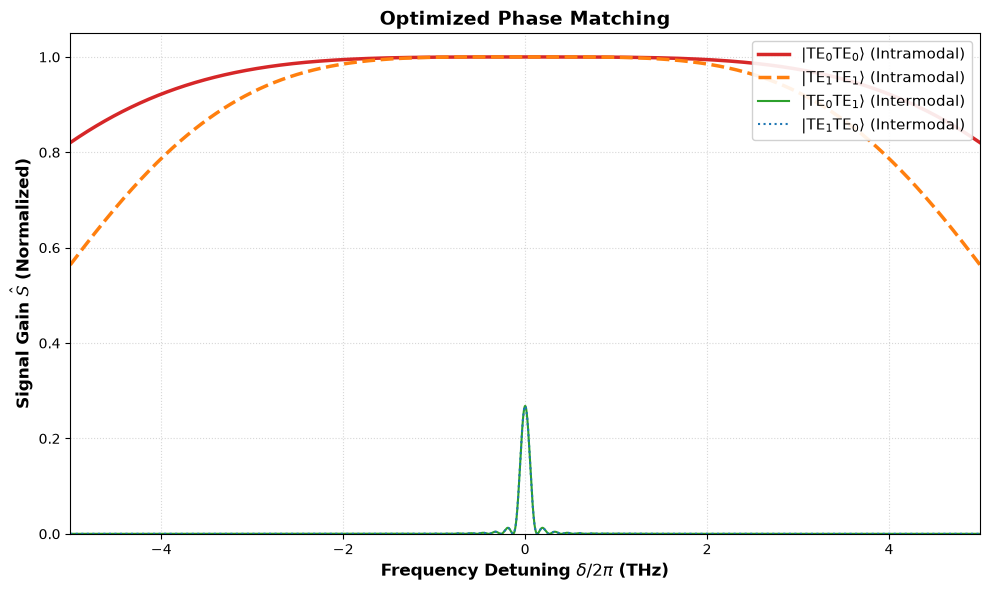

In [6]:
# ==============================================================================
# 9. POWER BALANCE FOR MAXIMUM ENANGLEMENT STATE (Eq. 3 OF FENG ET AL.)
# ==============================================================================
# PHYSICAL OBJECTIVE:
# To generate a maximally entangled Bell state |Phi^+> = (1/sqrt(2)) * (|TE0 TE0> + |TE1 TE1>),
# the probability amplitudes of both intramodal processes must be identical (eta_3 = 1).
# Given that the fundamental TE0 mode has higher electromagnetic confinement (gamma_TE0 > gamma_TE1),
# its natural pair generation probability is higher. To compensate for this asymmetry, we must
# split the total pump power (P_pump) and inject proportionally higher energy into the TE1 mode.

# Calculation of the ratio between the nonlinear (Kerr) coefficients of both modes
gamma_ratio = gamma_TE0 / gamma_TE1  # Represents the correction factor for confinement asymmetry

# Analytical distribution of total injected power (P_pump) ensuring energy conservation:
# From condition eta_3 = (gamma_TE0 * P_TE0) / (gamma_TE1 * P_TE1) = 1  ==> P_TE1 = P_TE0 * (gamma_TE0 / gamma_TE1)
# Knowing P_TE0 + P_TE1 = P_pump, we analytically solve for the powers of each mode:
P_TE0_bal = P_pump / (1 + gamma_ratio)               # Power assigned to TE0 mode (lower power due to higher gamma)
P_TE1_bal = P_pump * gamma_ratio / (1 + gamma_ratio) # Power assigned to TE1 mode (higher power to compensate)

# Descriptive console printout of optical powers in milliwatts (mW)
print("\n" + "=" * 65)
print(" POWER DISTRIBUTION FOR MAXIMUM ENTANGLEMENT (eta_3=1)")
print("=" * 65)
print(f"Total pump power   : {P_pump * 1000:.1f} mW")
print(f"Required power in TE0: {P_TE0_bal * 1000:.2f} mW")
print(f"Required power in TE1: {P_TE1_bal * 1000:.2f} mW")
print(f"Ratio (P_TE1 / P_TE0) : {P_TE1_bal / P_TE0_bal:.3f}")
print("=" * 65)

# ------------------------------------------------------------------------------
# 1. DEFINITION OF WIDE DETUNING RANGE AND DISPERSION EVALUATION
# ------------------------------------------------------------------------------
# Creation of frequency detuning vector f_detuning (delta / 2pi) in Terahertz (THz)
# Defines a symmetric mesh of 2000 points in the spectral range from -6.0 THz to +6.0 THz relative to pump
f_detuning_wide = np.linspace(-10.0, 10.0, 50000)  

# Conversion of linear frequency detuning (THz) to angular frequency in rad/s (delta_omega)
delta_omega_wide = 2 * np.pi * f_detuning_wide * 1e12

# Strict application of energy conservation law for photons generated by SFWM:
# Angular frequency of up-shifted signal photon: omega_s = omega_p + delta_omega
omega_s_w = omega_p + delta_omega_wide
# Angular frequency of down-shifted idler photon: omega_i = omega_p - delta_omega
omega_i_w = omega_p - delta_omega_wide

# Exact evaluation of propagation constants beta(omega) in rad/m via Spline functions
# Calculation of linear phase mismatch (Delta k = beta_s + beta_i - beta_p1 - beta_p2) for the 4 processes:

# Process 1: Intramodal TE0 TE0 (Signal in TE0, Idler in TE0, both Pumps in TE0)
dk_00_w = spline_beta0(omega_s_w) + spline_beta0(omega_i_w) - 2 * spline_beta0(omega_p)

# Process 2: Intramodal TE1 TE1 (Signal in TE1, Idler in TE1, both Pumps in TE1)
dk_11_w = spline_beta1(omega_s_w) + spline_beta1(omega_i_w) - 2 * spline_beta1(omega_p)

# Process 3: Intermodal Type III TE0 TE1 (Signal in TE0, Idler in TE1, Pumps in TE0 and TE1)
dk_01_w = spline_beta0(omega_s_w) + spline_beta1(omega_i_w) - spline_beta0(omega_p) - spline_beta1(omega_p)

# Process 4: Intermodal Type III TE1 TE0 (Signal in TE1, Idler in TE0, Pumps in TE0 and TE1)
dk_10_w = spline_beta1(omega_s_w) + spline_beta0(omega_i_w) - spline_beta0(omega_p) - spline_beta1(omega_p)

# ------------------------------------------------------------------------------
# 2. SPECTRUM RE-CALCULATION WITH OPTIMIZED POWERS (BALANCED SFWM)
# ------------------------------------------------------------------------------
# For cross-phase modulation in intermodal processes (Type III), the effective pump power
# equals the geometric mean of the powers injected into each mode: P_cross = sqrt(P_TE0 * P_TE1)
P_cross_bal = np.sqrt(P_TE0_bal * P_TE1_bal)

# Evaluation of parametric gain and generation rate n_s using robust complex function calculate_ns:
ns_00_bal = calculate_ns(dk_00_w, gamma_TE0, P_TE0_bal, L_waveguide)   # Generation of |TE0 TE0> pair
ns_11_bal = calculate_ns(dk_11_w, gamma_TE1, P_TE1_bal, L_waveguide)   # Generation of |TE1 TE1> pair
ns_01_bal = calculate_ns(dk_01_w, gamma_Cross, P_cross_bal, L_waveguide)# Generation of |TE0 TE1> pair
ns_10_bal = calculate_ns(dk_10_w, gamma_Cross, P_cross_bal, L_waveguide)# Generation of |TE1 TE0> pair

# Extraction of global maximum value of the balanced spectrum.
# Having equalized the weighted powers, np.max(ns_00_bal) and np.max(ns_11_bal) are mathematically identical.
max_val_bal = np.max(ns_00_bal)

# ------------------------------------------------------------------------------
# 3. PUBLICATION-READY PLOTTING OF BALANCED SPECTRUM
# ------------------------------------------------------------------------------
# Initialization of Matplotlib figure with 10x6 inches canvas dimensions
fig3, ax3 = plt.subplots(figsize=(10, 6))

# Plotting normalized spectral curves (S_hat = n_s / max_val_bal):
# 1. Intramodal TE0 TE0 mode (Solid red line)
ax3.plot(f_detuning_wide, ns_00_bal / max_val_bal, label=r"$|\mathrm{TE}_0 \mathrm{TE}_0\rangle$ (Intramodal)", color="tab:red", lw=2.5)

# 2. Intramodal TE1 TE1 mode (Dashed orange line - Notice how it overlaps exactly at 1.0 at delta=0)
ax3.plot(f_detuning_wide, ns_11_bal / max_val_bal, label=r"$|\mathrm{TE}_1 \mathrm{TE}_1\rangle$ (Intramodal)", color="tab:orange", lw=2.5, linestyle="--")

# 3. Intermodal TE0 TE1 mode (Solid green line)
ax3.plot(f_detuning_wide, ns_01_bal / max_val_bal, label=r"$|\mathrm{TE}_0 \mathrm{TE}_1\rangle$ (Intermodal)", color="tab:green", lw=1.5)

# 4. Intermodal TE1 TE0 mode (Thin blue dotted line)
ax3.plot(f_detuning_wide, ns_10_bal / max_val_bal, label=r"$|\mathrm{TE}_1 \mathrm{TE}_0\rangle$ (Intermodal)", color="tab:blue", lw=1.5, linestyle=":")

# Configuration of titles and axis labels in LaTeX format
ax3.set_title("Optimized Phase Matching", fontsize=14, fontweight="bold")
ax3.set_xlabel(r"Frequency Detuning $\delta / 2\pi$ (THz)", fontsize=12, fontweight="bold")
ax3.set_ylabel(r"Signal Gain $\hat{S}$ (Normalized)", fontsize=12, fontweight="bold")

# Definition of axis limits to focus on central region (-1.0 to +1.0 THz)
ax3.set_xlim(-5.0, 5.0)
ax3.set_ylim(0.0, 1.05)  # Keeps graphic ceiling at 1.05 to give visual headroom to the balanced peak

# Dotted grid and legend styling
ax3.grid(True, which="both", linestyle=":", alpha=0.5)
ax3.legend(fontsize=11, loc="upper right", framealpha=0.9)
plt.tight_layout()

# Final rendering of the plot on screen
plt.show()

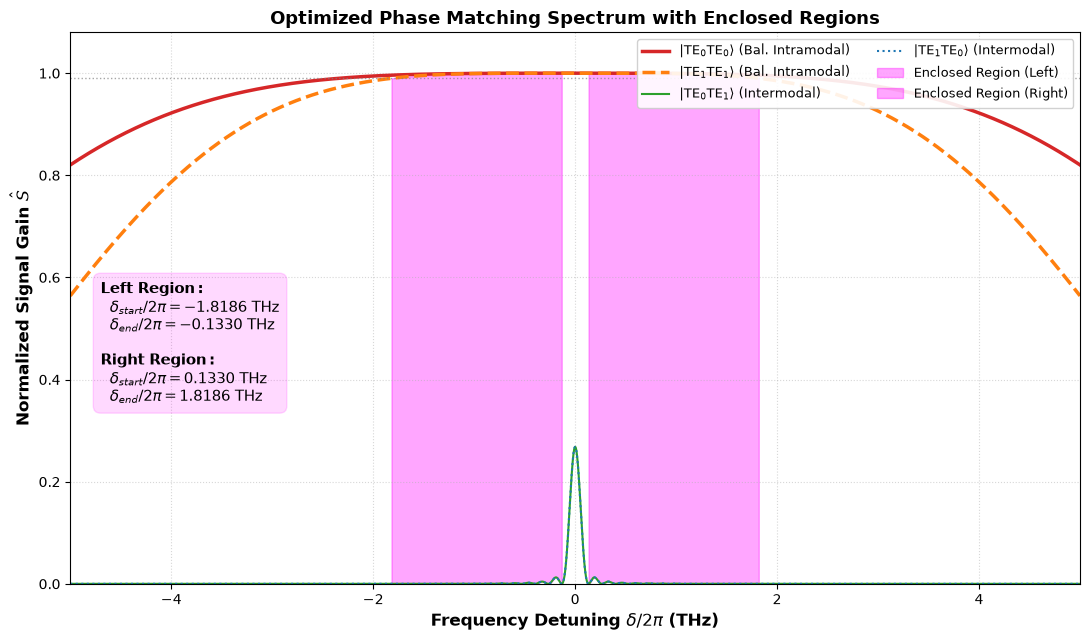

Left Region Limits : [-1.818636, -0.133003] THz
Right Region Limits: [0.133003, 1.818636] THz


In [7]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks

# ==============================================================================
# CALCULATION AND SHADING OF ENCLOSED AREA (TOWARDS THE EXTREMES)
# ==============================================================================

# Normalized curves of interest
y_bot_all = ns_01_bal / max_val_bal  
y_top_all = np.minimum(ns_00_bal, ns_11_bal) / max_val_bal  

# 1. Detection of first minimum of |TE0 TE1> curve
minima_indices, _ = find_peaks(-y_bot_all, distance=20, prominence=0.001)
minima_freqs = f_detuning_wide[minima_indices]

# Separate minima (left and right) and sort by closeness to center (0 THz)
left_min_mask = minima_freqs < 0
right_min_mask = minima_freqs > 0

left_indices = minima_indices[left_min_mask]
left_indices = left_indices[np.argsort(f_detuning_wide[left_indices])][::-1] 

right_indices = minima_indices[right_min_mask]
right_indices = right_indices[np.argsort(f_detuning_wide[right_indices])]    

# Take only the first minimum on each side
idx_min1_left = left_indices[0]
idx_min1_right = right_indices[0]

# Ranges: From first minimum extending towards edges
slice_left = slice(0, idx_min1_left + 1)
slice_right = slice(idx_min1_right, len(f_detuning_wide))

# 2. Filtering and extraction of detuning limits
def obtener_region_abierta(slice_region):
    f_sub = f_detuning_wide[slice_region]
    y_top_sub = y_top_all[slice_region]
    y_bot_sub = y_bot_all[slice_region]
    
    # Includes everything above 0.99
    mask_095 = y_top_sub >= 0.99
    
    f_valid = f_sub[mask_095]
    y_top_valid = y_top_sub[mask_095]
    y_bot_valid = y_bot_sub[mask_095]
    
    if len(f_valid) < 2:
        return np.array([]), np.array([]), np.array([]), None, None
        
    f_start = f_valid[0]
    f_end = f_valid[-1]
    
    return f_valid, y_top_valid, y_bot_valid, f_start, f_end

f_valid_L, y_top_L, y_bot_L, f_start_L, f_end_L = obtener_region_abierta(slice_left)
f_valid_R, y_top_R, y_bot_R, f_start_R, f_end_R = obtener_region_abierta(slice_right)

# ------------------------------------------------------------------------------
# 3. PUBLICATION-READY PLOTTING IN ENGLISH
# ------------------------------------------------------------------------------
fig3, ax3 = plt.subplots(figsize=(11, 6.5))

# Intramodal Modes
ax3.plot(f_detuning_wide, ns_00_bal / max_val_bal, label=r"$|\mathrm{TE}_0 \mathrm{TE}_0\rangle$ (Bal. Intramodal)", color="tab:red", lw=2.5)
ax3.plot(f_detuning_wide, ns_11_bal / max_val_bal, label=r"$|\mathrm{TE}_1 \mathrm{TE}_1\rangle$ (Bal. Intramodal)", color="tab:orange", lw=2.5, linestyle="--")

# Intermodal Modes
ax3.plot(f_detuning_wide, ns_01_bal / max_val_bal, label=r"$|\mathrm{TE}_0 \mathrm{TE}_1\rangle$ (Intermodal)", color="tab:green", lw=1.5)
ax3.plot(f_detuning_wide, ns_10_bal / max_val_bal, label=r"$|\mathrm{TE}_1 \mathrm{TE}_0\rangle$ (Intermodal)", color="tab:blue", lw=1.5, linestyle=":")

# Magenta shading
if f_start_L is not None:
    ax3.fill_between(f_valid_L, y_bot_L, y_top_L, color="magenta", alpha=0.35, label="Enclosed Region (Left)")
if f_start_R is not None:
    ax3.fill_between(f_valid_R, y_bot_R, y_top_R, color="magenta", alpha=0.35, label="Enclosed Region (Right)")

# Threshold line at 0.99
ax3.axhline(0.99, color="gray", linestyle=":", linewidth=1.0, alpha=0.7)

# Text box with frequency ranges using raw f-strings (fr"...")
textstr = (
    r"$\mathbf{Left\ Region:}$" + "\n"
    fr"  $\delta_{{start}}/2\pi = {f_start_L:.4f}$ THz" + "\n"
    fr"  $\delta_{{end}}/2\pi = {f_end_L:.4f}$ THz" + "\n\n"
    r"$\mathbf{Right\ Region:}$" + "\n"
    fr"  $\delta_{{start}}/2\pi = {f_start_R:.4f}$ THz" + "\n"
    fr"  $\delta_{{end}}/2\pi = {f_end_R:.4f}$ THz"
)
props = dict(boxstyle="round,pad=0.5", facecolor="magenta", alpha=0.15, edgecolor="magenta")
ax3.text(0.03, 0.55, textstr, transform=ax3.transAxes, fontsize=10.5, verticalalignment="top", bbox=props)

# Axis configuration and titles in English
ax3.set_title("Optimized Phase Matching Spectrum with Enclosed Regions", fontsize=13, fontweight="bold")
ax3.set_xlabel(r"Frequency Detuning $\delta / 2\pi$ (THz)", fontsize=12, fontweight="bold")
ax3.set_ylabel(r"Normalized Signal Gain $\hat{S}$", fontsize=12, fontweight="bold")

# X-axis limits matching image (-5 to 5 THz)
ax3.set_xlim(-5.0, 5.0)
ax3.set_ylim(0.0, 1.08)

ax3.grid(True, which="both", linestyle=":", alpha=0.5)

# Legend label control to avoid duplicates
handles, labels = ax3.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax3.legend(by_label.values(), by_label.keys(), fontsize=9.5, loc="upper right", framealpha=0.9, ncol=2)

plt.tight_layout()
plt.show()

print(f"Left Region Limits : [{f_start_L:.6f}, {f_end_L:.6f}] THz")
print(f"Right Region Limits: [{f_start_R:.6f}, {f_end_R:.6f}] THz")

1. Calculating modal dispersion with MPB...
2. Calculating global optimization curve (0.5 to 2.0 cm)...
Showing optimal spectrum for L_opt = 1.29 cm...


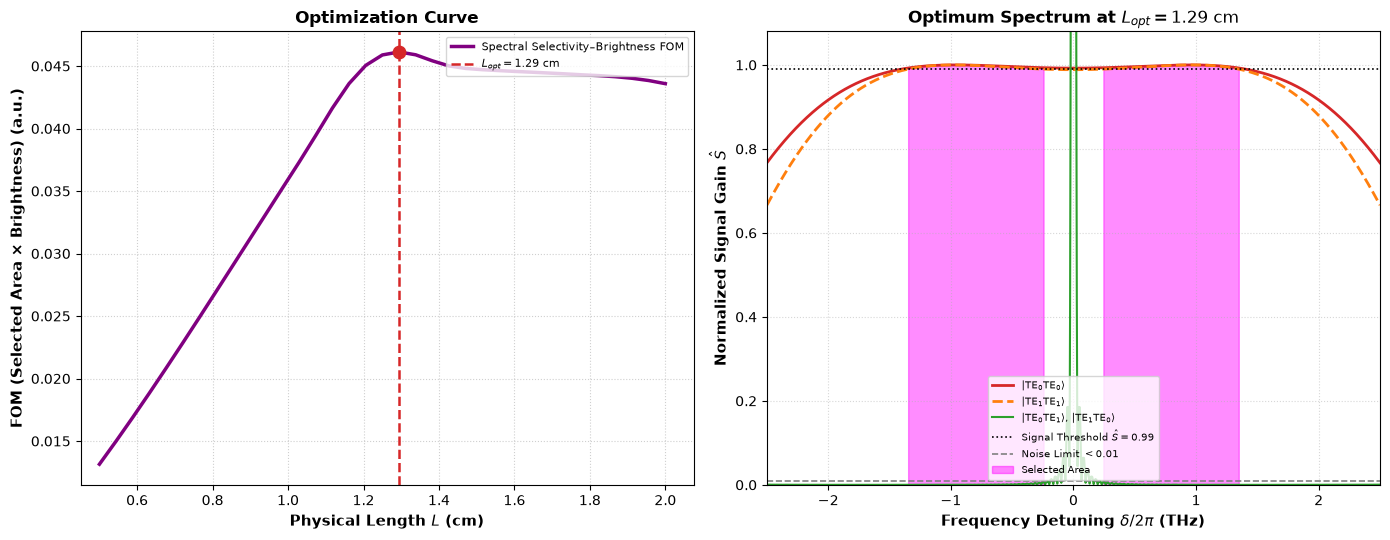

3. Calculating modal loss models comparison...


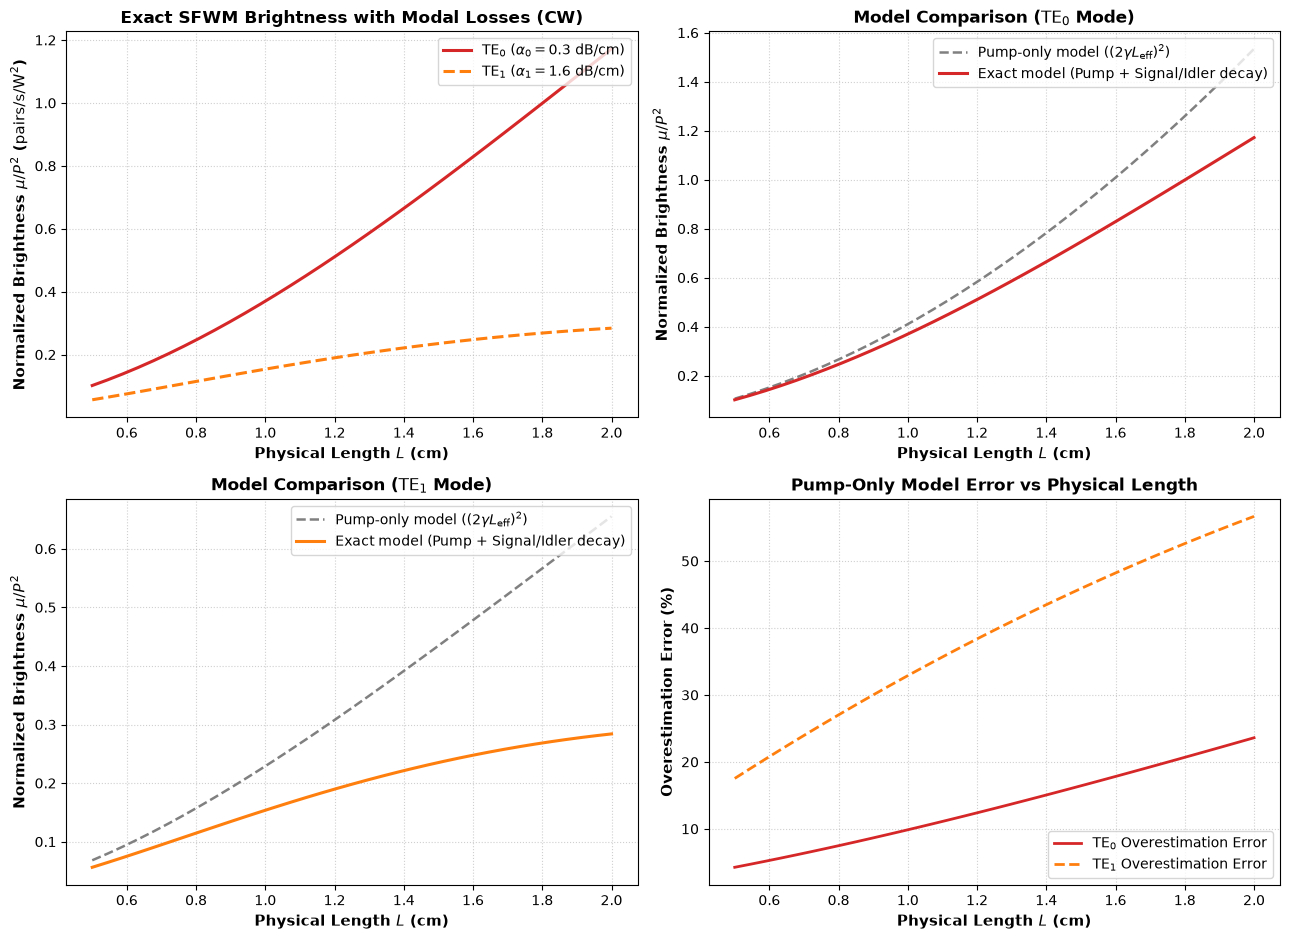

4. Calculating DWDM mapping and generation by spectral channel...


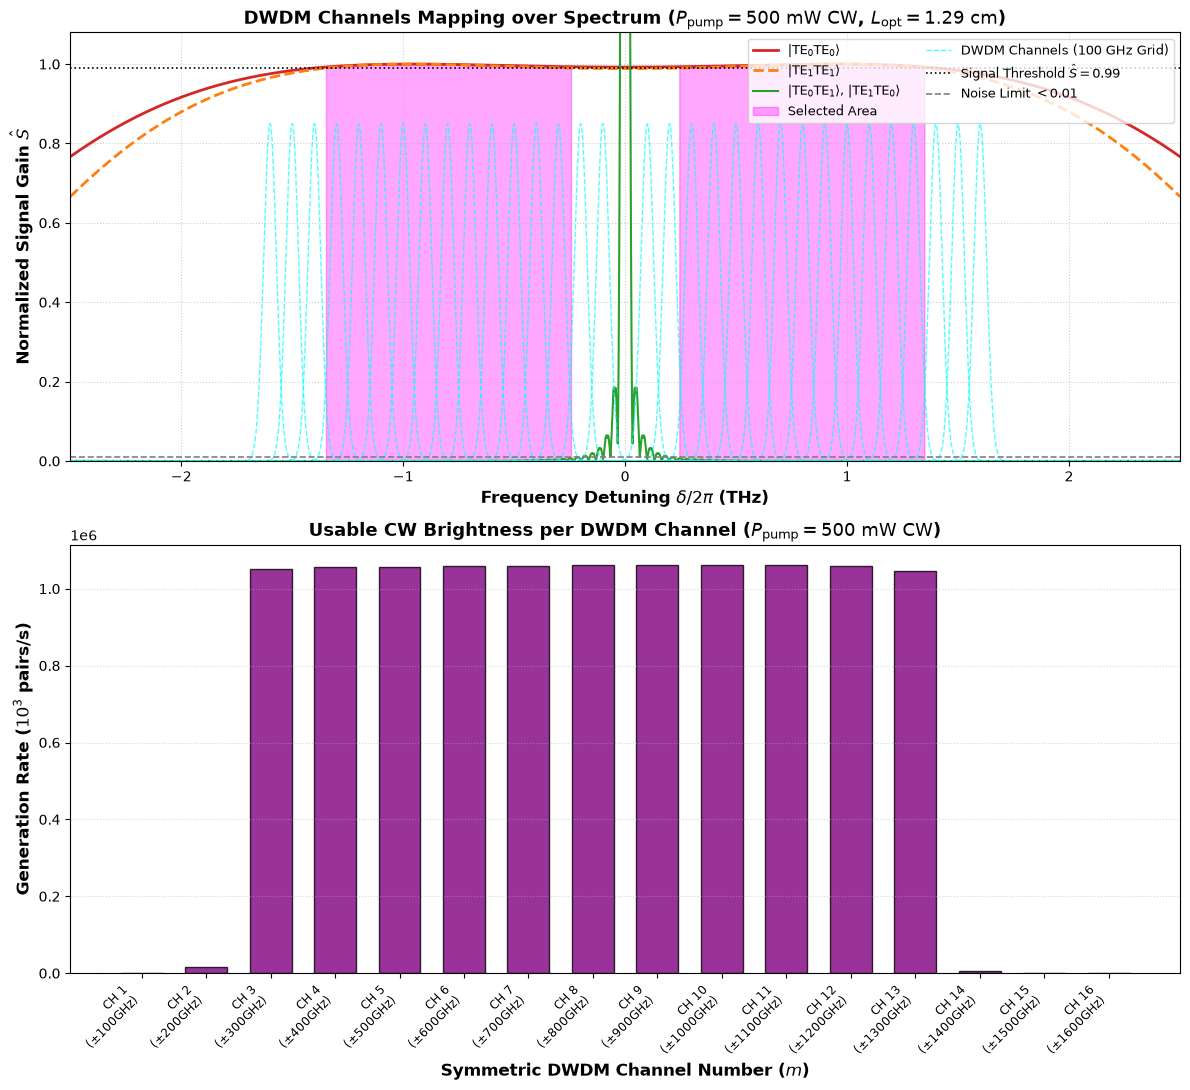

In [8]:
import os
import matplotlib.pyplot as plt
import meep as mp
from meep import mpb
import numpy as np
from scipy.integrate import trapezoid
from scipy.interpolate import CubicSpline
from scipy.ndimage import label
from scipy.optimize import brentq
from scipy.signal import savgol_filter

# Silence MEEP I/O
mp.verbosity(0)

# ==============================================================================
# 0. SINGLE LENGTH CONFIGURATION
# ==============================================================================
L_min_cm = 0.5
L_max_cm = 2.0

# ==============================================================================
# 1. GEOMETRIC AND PHYSICAL PARAMETERS
# ==============================================================================
w_waveguide = 0.760
h_waveguide = 0.220

wavelength_p = 1.55011e-6
c = 299792458.0
omega_p = (2.0 * np.pi * c) / wavelength_p

# Attenuations
loss_TE0_dBcm = 0.3
loss_TE1_dBcm = 1.6
alpha_TE0 = loss_TE0_dBcm * (np.log(10.0) / 10.0) * 100.0
alpha_TE1 = loss_TE1_dBcm * (np.log(10.0) / 10.0) * 100.0

# Nonlinear coefficients
gamma_TE0 = 66.3
gamma_TE1 = 57.2
gamma_Cross = 61.0
P_pump = 0.50  # Total power in W

# Frequency sampling
f_detuning = np.linspace(-4.0, 4.0, 25000)

def n_Si(l_um):
    l2 = l_um**2
    return np.sqrt(1.0 + (10.6684293 * l2) / (l2 - 0.301516485**2) + 
                   (0.00304347484 * l2) / (l2 - 1.13475115**2) + 
                   (1.54133408 * l2) / (l2 - 1104.0**2))

def n_SiO2(l_um):
    l2 = l_um**2
    return np.sqrt(1.0 + (0.663472443 * l2) / (l2 - 0.0665176613**2) + 
                   (0.440647918 * l2) / (l2 - 0.115015076**2) + 
                   (0.990316809 * l2) / (l2 - 9.90316809**2))

# ==============================================================================
# 2. ULTRA-FAST DISPERSION CALCULATION (\beta(\omega) VIA MPB)
# ==============================================================================
print("1. Calculating modal dispersion with MPB...")
sx, sy = 3.0, 2.0
resolution = 16
geometry_lattice = mp.Lattice(size=mp.Vector3(sx, sy, 0))

ms = mpb.ModeSolver(
    geometry_lattice=geometry_lattice,
    geometry=[],
    resolution=resolution,
    num_bands=2,
)

lambdas_um = np.linspace(1.400, 1.700, 15)
kz_TE0_list, kz_TE1_list = [], []

for l in lambdas_um:
    freq_l = 1.0 / l
    n_core, n_clad = n_Si(l), n_SiO2(l)

    ms.geometry = [
        mp.Block(center=mp.Vector3(0, 0, 0), size=mp.Vector3(mp.inf, mp.inf, mp.inf), material=mp.Medium(index=n_clad)),
        mp.Block(center=mp.Vector3(0, 0, 0), size=mp.Vector3(w_waveguide, h_waveguide, mp.inf), material=mp.Medium(index=n_core)),
    ]
    ms.init_params(mp.NO_PARITY, reset_fields=True)

    k_res_1 = ms.find_k(mp.NO_PARITY, freq_l, 1, 1, mp.Vector3(0, 0, 1), 1e-4, freq_l * n_core, 0.1, 4.0)
    kz_TE0_list.append(k_res_1[0])

    k_res_2 = ms.find_k(mp.NO_PARITY, freq_l, 2, 2, mp.Vector3(0, 0, 1), 1e-4, freq_l * (n_core - 0.5), 0.1, 4.0)
    kz_TE1_list.append(k_res_2[0])

omega = (2 * np.pi * c) / (lambdas_um * 1e-6)
spline_beta0 = CubicSpline(omega[::-1], np.array(kz_TE0_list)[::-1] * (2 * np.pi / 1e-6))
spline_beta1 = CubicSpline(omega[::-1], np.array(kz_TE1_list)[::-1] * (2 * np.pi / 1e-6))

w_d = 2.0 * np.pi * f_detuning * 1e12
omega_s, omega_i = omega_p + w_d, omega_p - w_d

dk_00_lin = 2.0 * spline_beta0(omega_p) - spline_beta0(omega_s) - spline_beta0(omega_i)
dk_11_lin = 2.0 * spline_beta1(omega_p) - spline_beta1(omega_s) - spline_beta1(omega_i)
dk_01_lin = spline_beta0(omega_p) + spline_beta1(omega_p) - spline_beta0(omega_s) - spline_beta1(omega_i)
dk_10_lin = spline_beta0(omega_p) + spline_beta1(omega_p) - spline_beta1(omega_s) - spline_beta0(omega_i)

# ==============================================================================
# 3. RIGOROUS INTEGRAL ENGINE 
# ==============================================================================
def calculate_ns_fast(dk_lin, gamma, P0, alpha_pump_amp, alpha_p0_phase, alpha_s, alpha_i, L, is_cross=False, P1=0.0, alpha_p1_phase=0.0):
    Nz = 100
    z = np.linspace(0, L, Nz)
    alpha_avg = (alpha_s + alpha_i) / 2.0
    g_eff = 2.0 * gamma if is_cross else gamma

    if not is_cross:
        phi_NL = 2.0 * gamma * P0 * (1.0 - np.exp(-alpha_p0_phase * z)) / (alpha_p0_phase + 1e-12)
    else:
        phi_NL = (2.0 * gamma_Cross * P0 * (1.0 - np.exp(-alpha_p0_phase * z)) / (alpha_p0_phase + 1e-12)) + \
                 (2.0 * gamma_Cross * P1 * (1.0 - np.exp(-alpha_p1_phase * z)) / (alpha_p1_phase + 1e-12))

    z_grid = z[:, np.newaxis]
    phi_total = dk_lin[np.newaxis, :] * z_grid + phi_NL[:, np.newaxis]
    
    amplitude_decay = np.exp(-alpha_pump_amp * z_grid) * np.exp(-alpha_avg * (L - z_grid))

    integrand = amplitude_decay * np.exp(1j * phi_total)
    integral = trapezoid(integrand, x=z, axis=0)

    P_eff = P0 if not is_cross else np.sqrt(P0 * P1)
    return np.abs(g_eff * P_eff * integral) ** 2


def evaluar_longitud_multiregion(L, f_det):
    def diff_amplitudes(p0):
        p1 = P_pump - p0
        ns_00_full = calculate_ns_fast(dk_00_lin, gamma_TE0, p0, alpha_TE0, alpha_TE0, alpha_TE0, alpha_TE0, L)
        ns_11_full = calculate_ns_fast(dk_11_lin, gamma_TE1, p1, alpha_TE1, alpha_TE1, alpha_TE1, alpha_TE1, L)
        return np.max(ns_00_full) - np.max(ns_11_full)

    diff_Pmin = diff_amplitudes(1e-5)
    diff_Pmax = diff_amplitudes(P_pump - 1e-5)
    
    if diff_Pmin * diff_Pmax > 0:
        if abs(diff_Pmin) < abs(diff_Pmax):
            P0_bal = 1e-5
        else:
            P0_bal = P_pump - 1e-5
    else:
        P0_bal = brentq(diff_amplitudes, 1e-5, P_pump - 1e-5, xtol=1e-5)

    P1_bal = P_pump - P0_bal

    ns_00 = calculate_ns_fast(dk_00_lin, gamma_TE0, P0_bal, alpha_TE0, alpha_TE0, alpha_TE0, alpha_TE0, L)
    ns_11 = calculate_ns_fast(dk_11_lin, gamma_TE1, P1_bal, alpha_TE1, alpha_TE1, alpha_TE1, alpha_TE1, L)

    alpha_cross = (alpha_TE0 + alpha_TE1) / 2.0
    ns_01 = calculate_ns_fast(dk_01_lin, gamma_Cross, P0_bal, alpha_cross, alpha_TE0, alpha_TE0, alpha_TE1, L, True, P1_bal, alpha_TE1)
    ns_10 = calculate_ns_fast(dk_10_lin, gamma_Cross, P1_bal, alpha_cross, alpha_TE1, alpha_TE1, alpha_TE0, L, True, P0_bal, alpha_TE0)

    max_val_abs = np.max(ns_00)
    if max_val_abs < 1e-18:
        return 0.0, (np.zeros_like(f_det), np.zeros_like(f_det), np.zeros_like(f_det), np.zeros_like(f_det, dtype=bool), P0_bal, P1_bal, ns_00)

    y_00_norm = ns_00 / max_val_abs
    y_11_norm = ns_11 / max_val_abs
    y_bot = np.maximum(ns_01 / max_val_abs, ns_10 / max_val_abs)

    raw_condition = (y_00_norm >= 0.99) & (y_11_norm >= 0.99) & (y_bot < 0.01)
    labeled, num_features = label(raw_condition)
    mask_pure = np.zeros_like(raw_condition, dtype=bool)
    overlap_min = np.minimum(y_00_norm, y_11_norm)
    area_pure = 0.0

    for region_id in range(1, num_features + 1):
        region_mask = labeled == region_id
        if np.sum(region_mask) > 5:
            area_pure += trapezoid(overlap_min[region_mask], f_det[region_mask])
            mask_pure |= region_mask

    ratio_picos = np.min([np.max(ns_00), np.max(ns_11)]) / np.max([np.max(ns_00), np.max(ns_11)])
    
    return (area_pure * max_val_abs * ratio_picos), (y_00_norm, y_11_norm, y_bot, mask_pure, P0_bal, P1_bal, ns_00)

# ==============================================================================
# 4. OPTIMIZATION AND FIGURE 1 (OPTIMIZATION CURVE AND OPTIMAL SPECTRUM)
# ==============================================================================
print(f"2. Calculating global optimization curve ({L_min_cm} to {L_max_cm} cm)...")
L_sweep_cm = np.linspace(L_min_cm, L_max_cm, 35)  
L_sweep_m = L_sweep_cm * 1e-2

raw_fom = [evaluar_longitud_multiregion(L_m, f_detuning)[0] for L_m in L_sweep_m]

raw_fom = np.array(raw_fom)
smooth_fom = savgol_filter(raw_fom, window_length=9, polyorder=3)
smooth_fom = np.maximum(0.0, np.where(raw_fom == 0, 0.0, smooth_fom))

best_idx = np.argmax(smooth_fom)
best_L_cm, best_fom = L_sweep_cm[best_idx], smooth_fom[best_idx]
best_L_m = best_L_cm * 1e-2

def generar_figura_1(target_cm):
    target_m = target_cm * 1e-2
    _, data_test = evaluar_longitud_multiregion(target_m, f_detuning)
    y00_t, y11_t, y_bot_t, mask_t, P0_t, P1_t, _ = data_test

    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

    axes[0].plot(L_sweep_cm, smooth_fom, color="purple", lw=2.5, label=r"Spectral Selectivity–Brightness FOM")
    axes[0].axvline(best_L_cm, color="tab:red", linestyle="--", lw=1.8, label=f"$L_{{opt}} = {best_L_cm:.2f}\\text{{ cm}}$")
    axes[0].scatter([best_L_cm], [best_fom], color="tab:red", s=80, zorder=5)
    axes[0].set_xlim(max(0.1, L_min_cm - 0.05), L_max_cm + 0.05 * (L_max_cm - L_min_cm))
    axes[0].set_xlabel("Physical Length $L$ (cm)", fontsize=11, fontweight="bold")
    axes[0].set_ylabel("FOM (Selected Area × Brightness) (a.u.)", fontsize=11, fontweight="bold")
    axes[0].set_title("Optimization Curve", fontsize=12, fontweight="bold")
    axes[0].grid(True, linestyle=":", alpha=0.6)
    axes[0].legend(fontsize=8, loc="upper right")

    axes[1].plot(f_detuning, y00_t, label=r"$|\mathrm{TE}_0 \mathrm{TE}_0\rangle$", color="tab:red", lw=2.0)
    axes[1].plot(f_detuning, y11_t, label=r"$|\mathrm{TE}_1 \mathrm{TE}_1\rangle$", color="tab:orange", lw=2.0, linestyle="--")
    axes[1].plot(f_detuning, y_bot_t, label=r"$|\mathrm{TE}_0 \mathrm{TE}_1\rangle$, $|\mathrm{TE}_1 \mathrm{TE}_0\rangle$", color="tab:green", lw=1.5)
    axes[1].axhline(0.99, color="black", linestyle=":", lw=1.2, label=r"Signal Threshold $\hat{S} = 0.99$")
    axes[1].axhline(0.01, color="gray", linestyle="--", lw=1.2, label=r"Noise Limit $< 0.01$")

    if np.any(mask_t):
        y_overlap = np.minimum(y00_t, y11_t)
        labeled_mask, num_regions = label(mask_t)
        for reg_id in range(1, num_regions + 1):
            reg_mask = labeled_mask == reg_id
            if np.sum(reg_mask) > 5:
                axes[1].fill_between(f_detuning[reg_mask], 0, y_overlap[reg_mask], color="magenta", alpha=0.45, label="Selected Area" if reg_id == 1 else "")

    axes[1].set_xlabel(r"Frequency Detuning $\delta / 2\pi$ (THz)", fontsize=11, fontweight="bold")
    axes[1].set_ylabel(r"Normalized Signal Gain $\hat{S}$", fontsize=11, fontweight="bold")
    axes[1].set_title(f"Optimum Spectrum at $L_{{opt}} = {best_L_cm:.2f}\\text{{ cm}}$", fontsize=12, fontweight="bold")
    axes[1].set_xlim(-2.5, 2.5)
    axes[1].set_ylim(0.0, 1.08)
    axes[1].grid(True, linestyle=":", alpha=0.5)
    axes[1].legend(fontsize=7.5, loc="lower center")

    plt.tight_layout()
    plt.show()

print(f"Showing optimal spectrum for L_opt = {best_L_cm:.2f} cm...")
generar_figura_1(best_L_cm)

# ==============================================================================
# 5. FIGURE 2: MODAL LOSS MODELS COMPARISON (2x2 GRAPHS)
# ==============================================================================
print("3. Calculating modal loss models comparison...")

mu_exact_TE0 = np.array([
    calculate_ns_fast(np.array([0.0]), gamma_TE0, P_pump, alpha_TE0, alpha_TE0, alpha_TE0, alpha_TE0, L_m)[0]
    for L_m in L_sweep_m
])
mu_exact_TE1 = np.array([
    calculate_ns_fast(np.array([0.0]), gamma_TE1, P_pump, alpha_TE1, alpha_TE1, alpha_TE1, alpha_TE1, L_m)[0]
    for L_m in L_sweep_m
])

L_eff_TE0 = (1.0 - np.exp(-alpha_TE0 * L_sweep_m)) / alpha_TE0
mu_simplified_TE0 = (gamma_TE0 * P_pump * L_eff_TE0) ** 2

L_eff_TE1 = (1.0 - np.exp(-alpha_TE1 * L_sweep_m)) / alpha_TE1
mu_simplified_TE1 = (gamma_TE1 * P_pump * L_eff_TE1) ** 2

fig2, axes2 = plt.subplots(2, 2, figsize=(13, 9.5))

ax = axes2[0, 0]
ax.plot(L_sweep_cm, mu_exact_TE0 / (P_pump**2), label=rf"$\mathrm{{TE}}_0$ ($\alpha_0 = {loss_TE0_dBcm:.1f}\ \mathrm{{dB/cm}}$)", color="tab:red", lw=2.2)
ax.plot(L_sweep_cm, mu_exact_TE1 / (P_pump**2), label=rf"$\mathrm{{TE}}_1$ ($\alpha_1 = {loss_TE1_dBcm:.1f}\ \mathrm{{dB/cm}}$)", color="tab:orange", lw=2.2, linestyle="--")
ax.set_xlabel("Physical Length $L$ (cm)", fontsize=11, fontweight="bold")
ax.set_ylabel(r"Normalized Brightness $\mu / P^2$ ($\mathrm{pairs/s/W}^2$)", fontsize=11, fontweight="bold")
ax.set_title("Exact SFWM Brightness with Modal Losses (CW)", fontsize=12, fontweight="bold")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(fontsize=10, loc="upper right")

ax = axes2[0, 1]
ax.plot(L_sweep_cm, mu_simplified_TE0 / (P_pump**2), label=r"Pump-only model ($(2\gamma L_{\mathrm{eff}})^2$)", color="gray", linestyle="--", lw=1.8)
ax.plot(L_sweep_cm, mu_exact_TE0 / (P_pump**2), label=r"Exact model (Pump + Signal/Idler decay)", color="tab:red", lw=2.2)
ax.set_xlabel("Physical Length $L$ (cm)", fontsize=11, fontweight="bold")
ax.set_ylabel(r"Normalized Brightness $\mu / P^2$", fontsize=11, fontweight="bold")
ax.set_title(r"Model Comparison ($\mathrm{TE}_0$ Mode)", fontsize=12, fontweight="bold")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(fontsize=10, loc="upper right")

ax = axes2[1, 0]
ax.plot(L_sweep_cm, mu_simplified_TE1 / (P_pump**2), label=r"Pump-only model ($(2\gamma L_{\mathrm{eff}})^2$)", color="gray", linestyle="--", lw=1.8)
ax.plot(L_sweep_cm, mu_exact_TE1 / (P_pump**2), label=r"Exact model (Pump + Signal/Idler decay)", color="tab:orange", lw=2.2)
ax.set_xlabel("Physical Length $L$ (cm)", fontsize=11, fontweight="bold")
ax.set_ylabel(r"Normalized Brightness $\mu / P^2$", fontsize=11, fontweight="bold")
ax.set_title(r"Model Comparison ($\mathrm{TE}_1$ Mode)", fontsize=12, fontweight="bold")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(fontsize=10, loc="upper right")

diff_TE0 = (1.0 - mu_exact_TE0 / mu_simplified_TE0) * 100.0
diff_TE1 = (1.0 - mu_exact_TE1 / mu_simplified_TE1) * 100.0

ax = axes2[1, 1]
ax.plot(L_sweep_cm, diff_TE0, label=r"$\mathrm{TE}_0$ Overestimation Error", color="tab:red", lw=2.0)
ax.plot(L_sweep_cm, diff_TE1, label=r"$\mathrm{TE}_1$ Overestimation Error", color="tab:orange", lw=2.0, linestyle="--")
ax.set_xlabel("Physical Length $L$ (cm)", fontsize=11, fontweight="bold")
ax.set_ylabel("Overestimation Error (%)", fontsize=11, fontweight="bold")
ax.set_title("Pump-Only Model Error vs Physical Length", fontsize=12, fontweight="bold")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(fontsize=10, loc="lower right")

plt.tight_layout()
plt.show()

# ==============================================================================
# 6. FIGURE 3: DWDM SPECTRAL MAPPING AND CONTINUOUS GENERATION RATE PER CHANNEL
# ==============================================================================
print("4. Calculating DWDM mapping and generation by spectral channel...")

_, data_opt = evaluar_longitud_multiregion(best_L_m, f_detuning)
y00_opt, y11_opt, y_bot_opt, mask_opt, P0_opt, P1_opt, ns_00_opt = data_opt

fwhm_dwdm = 0.0672       # THz (67.2 GHz FWHM)
channel_spacing = 0.100  # THz (100 GHz)
num_channels = 16        # Increased to 22 channels to fully cover +- 2.2 THz

channel_indices = np.arange(1, num_channels + 1)
pairs_per_sec_channel = []
filter_transmissions_plot = []

ns_pure_spectrum = np.zeros_like(ns_00_opt)
if np.any(mask_opt):
    ns_pure_spectrum[mask_opt] = ns_00_opt[mask_opt]

for m in channel_indices:
    f_signal_center = m * channel_spacing
    f_idler_center = -m * channel_spacing
    
    # Filter applied to signal evaluated at f_detuning
    T_signal = np.exp(-4 * np.log(2) * ((f_detuning - f_signal_center) / fwhm_dwdm)**2)
    
    # Filter applied to idler evaluated at f_detuning for symmetric plotting
    T_idler  = np.exp(-4 * np.log(2) * ((f_detuning - f_idler_center) / fwhm_dwdm)**2)
    
    filter_transmissions_plot.append((f_signal_center, T_signal))
    filter_transmissions_plot.append((f_idler_center, T_idler))
    
    # Real coincidence: given a pair at (f_detuning, -f_detuning), 
    # the probability of passing both identical filters is T_signal ** 2
    T_coincidence = T_signal ** 2
    filtered_spectrum = ns_pure_spectrum * T_coincidence
    
    rate_m = trapezoid(filtered_spectrum, f_detuning * 1e12)
    pairs_per_sec_channel.append(rate_m)

pairs_per_sec_channel = np.array(pairs_per_sec_channel)

fig3, axes3 = plt.subplots(2, 1, figsize=(12, 11))

ax1 = axes3[0]
ax1.plot(f_detuning, y00_opt, label=r"$|\mathrm{TE}_0 \mathrm{TE}_0\rangle$", color="tab:red", lw=2.0)
ax1.plot(f_detuning, y11_opt, label=r"$|\mathrm{TE}_1 \mathrm{TE}_1\rangle$", color="tab:orange", lw=2.0, linestyle="--")
ax1.plot(f_detuning, y_bot_opt, label=r"$|\mathrm{TE}_0 \mathrm{TE}_1\rangle$, $|\mathrm{TE}_1 \mathrm{TE}_0\rangle$", color="tab:green", lw=1.5)

# Draw Selected Area respecting gaps via labeling
if np.any(mask_opt):
    y_overlap = np.minimum(y00_opt, y11_opt)
    labeled_mask, num_regions = label(mask_opt)
    for reg_id in range(1, num_regions + 1):
        reg_mask = labeled_mask == reg_id
        if np.sum(reg_mask) > 5:
            ax1.fill_between(f_detuning[reg_mask], 0, y_overlap[reg_mask], color="magenta", alpha=0.35, label="Selected Area" if reg_id == 1 else "")

# Draw overlapping filters
for idx, (f_c, T_filt) in enumerate(filter_transmissions_plot):
    lbl = "DWDM Channels (100 GHz Grid)" if idx == 0 else ""
    ax1.plot(f_detuning, T_filt * 0.85, color="cyan", linestyle="--", alpha=0.7, lw=1.0, label=lbl)

# Formal threshold lines
ax1.axhline(0.99, color="black", linestyle=":", lw=1.2, label=r"Signal Threshold $\hat{S} = 0.99$")
ax1.axhline(0.01, color="gray", linestyle="--", lw=1.2, label=r"Noise Limit $< 0.01$")

ax1.set_xlabel(r"Frequency Detuning $\delta / 2\pi$ (THz)", fontsize=12, fontweight="bold")
ax1.set_ylabel(r"Normalized Signal Gain $\hat{S}$", fontsize=12, fontweight="bold")
ax1.set_title(rf"DWDM Channels Mapping over Spectrum ($P_{{\mathrm{{pump}}}} = {P_pump*1000:.0f}\text{{ mW CW}}$, $L_{{\mathrm{{opt}}}} = {best_L_cm:.2f}\text{{ cm}}$)", fontsize=13, fontweight="bold")
ax1.set_xlim(-2.5, 2.5)
ax1.set_ylim(0.0, 1.08)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(fontsize=9, loc="upper right", ncol=2)

ax2 = axes3[1]
bars = ax2.bar(channel_indices, pairs_per_sec_channel / 1e3, color="purple", alpha=0.8, edgecolor="black", width=0.65)

ax2.set_xlabel("Symmetric DWDM Channel Number ($m$)", fontsize=12, fontweight="bold")
ax2.set_ylabel(r"Generation Rate ($10^3$ pairs/s)", fontsize=12, fontweight="bold")
ax2.set_title(rf"Usable CW Brightness per DWDM Channel ($P_{{\mathrm{{pump}}}} = {P_pump*1000:.0f}\text{{ mW CW}}$)", fontsize=13, fontweight="bold")
ax2.set_xticks(channel_indices)
ax2.set_xticklabels([f"CH {m}\n(±{m*100}GHz)" for m in channel_indices], fontsize=8.5, rotation=45, ha="right")
ax2.grid(True, linestyle=":", alpha=0.5, axis="y")

plt.tight_layout()
plt.show()